# Lab 11 — Simple Complete Solution
Keep `Tweets.csv` beside this notebook. Brief explanations are in `Lab11_Simplified_Notes.txt`.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, nltk
from collections import Counter
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from wordcloud import WordCloud

for item in ['stopwords', 'wordnet', 'vader_lexicon']:
    nltk.download(item, quiet=True)
plt.rcParams['figure.figsize'] = (7, 3)
pd.set_option('display.max_colwidth', 70)
df = pd.read_csv('Tweets.csv', dtype={'tweet_id': str})
df['date'] = pd.to_datetime(df['tweet_created'], utc=True)
tk = TweetTokenizer(preserve_case=False, reduce_len=True)
sia = SentimentIntensityAnalyzer()
def score(text):
    return sia.polarity_scores(text)['compound']
def label(value):
    return 'positive' if value >= .05 else 'negative' if value <= -.05 else 'neutral'

## Part A — Preparing Text
### A1 — Tokenizers and tweet features

In [2]:
examples = ['@Airline soooo happy :) #NotHappy https://example.com 😡']
for text in examples:
    print('Naive:', re.findall(r'\w+', text))
    print('Tweet-aware:', tk.tokenize(text))
features = {'handles': r'@\w+', 'hashtags': r'#\w+', 'links': r'https?://\S+',
            'emoji': r'[\U0001F300-\U0001FAFF]', 'stretched words': r'([a-z])\1{2,}'}
for feature, pattern in features.items():
    found = df['text'].apply(lambda t: bool(re.search(pattern, t, re.I)))
    print(feature, ':', found.sum(), '|', df.loc[found, 'text'].iloc[0][:75])
def clean(text):
    text = re.sub(r'https?://\S+|www\.\S+|@\w+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    return [w for w in tk.tokenize(text) if re.fullmatch(r"[a-z]+(?:'[a-z]+)?", w)]
df['tokens'] = df['text'].apply(clean)
display(df[['text', 'tokens']].head(2))

Naive: ['Airline', 'soooo', 'happy', 'NotHappy', 'https', 'example', 'com']
Tweet-aware: ['@airline', 'sooo', 'happy', ':)', '#nothappy', 'https://example.com', '😡']
handles : 14640 | @VirginAmerica What @dhepburn said.
hashtags : 2375 | @VirginAmerica @virginmedia I'm flying your #fabulous #Seductive skies agai
links : 1173 | @VirginAmerica Really missed a prime opportunity for Men Without Hats parod
emoji : 427 | I ❤️ flying @VirginAmerica. ☺️👍


stretched words : 117 | @VirginAmerica I love this graphic. http://t.co/UT5GrRwAaA


,text,tokens
0,@VirginAmerica What @dhepburn said.,"[what, said]"
1,@VirginAmerica plus you've added commercials to the experience... ...,"[plus, you've, added, commercials, to, the, experience, tacky]"


### A2 — Keep negation; test stop-word removal

In [3]:
standard = set(stopwords.words('english'))
negations = {'not', 'no', 'nor', 'never', 'neither', 'cannot'}
stops = {w for w in standard if w not in negations and not w.endswith("n't")}
def remove_stops(text, stop_list):
    return ' '.join(w for w in tk.tokenize(text) if w not in stop_list)
demo = pd.DataFrame({'text': ['The service is not good', 'The flight was not bad']})
demo['standard removal'] = demo.text.apply(lambda t: remove_stops(t, standard))
demo['score before'] = demo.text.apply(score)
demo['score after'] = demo['standard removal'].apply(score)
display(demo)
df['vader_score'] = df.text.apply(score)  # Always score the original tweet.
df['vader_label'] = df.vader_score.apply(label)
for name, stop_list in [('Standard', standard), ('Keep negation', stops)]:
    predictions = df.text.apply(lambda t: label(score(remove_stops(t, stop_list))))
    print(name, 'accuracy:', round((predictions == df.airline_sentiment).mean(), 3))
df['no_stop'] = df.tokens.apply(lambda words: [w for w in words if w not in stops])

,text,standard removal,score before,score after
0,The service is not good,service good,-0.3412,0.4404
1,The flight was not bad,flight bad,0.4310,-0.5423


Standard accuracy: 0.5


Keep negation accuracy: 0.537


### A3 — Stemming and lemmatization

In [4]:
stemmer = PorterStemmer()
lemma = WordNetLemmatizer()
def base(word):
    return lemma.lemmatize(lemma.lemmatize(word, 'v'), 'n')
words = ['flying', 'service', 'customers', 'delayed', 'caring']
display(pd.DataFrame({'word': words, 'stem': [stemmer.stem(w) for w in words],
                      'lemma': [base(w) for w in words]}))
df['stems'] = df.no_stop.apply(lambda ws: [stemmer.stem(w) for w in ws])
df['lemmas'] = df.no_stop.apply(lambda ws: [base(w) for w in ws])
for column in ['no_stop', 'stems', 'lemmas']:
    print(column, 'vocabulary:', len(set(w for ws in df[column] for w in ws)))

,word,stem,lemma
0,flying,fli,fly
1,service,servic,service
2,customers,custom,customer
3,delayed,delay,delay
4,caring,care,care


no_stop vocabulary: 10962
stems vocabulary: 8335
lemmas vocabulary: 8863


### A4 — Measure losses at each step

In [5]:
df['raw_tokens'] = df.text.apply(tk.tokenize)
audit = []
for column in ['raw_tokens', 'tokens', 'no_stop', 'lemmas']:
    lengths = df[column].apply(len)
    audit.append([column, len(set(w for ws in df[column] for w in ws)),
                  lengths.sum(), round(lengths.mean(), 1), (lengths == 0).sum()])
display(pd.DataFrame(audit, columns=['Step', 'Vocabulary', 'Tokens', 'Mean length', 'Empty']))

,Step,Vocabulary,Tokens,Mean length,Empty
0,raw_tokens,16874,294128,20.1,0
1,tokens,11124,231385,15.8,4
2,no_stop,10962,128803,8.8,26
3,lemmas,8863,128803,8.8,26


## Part B — Words and Phrases
### B1 — Raw versus cleaned words

Raw top tokens: [('.', 13740), ('to', 8648), ('the', 6060), ('i', 5452), ('!', 5080), ('?', 4608), ('a', 4501), (',', 4158)]


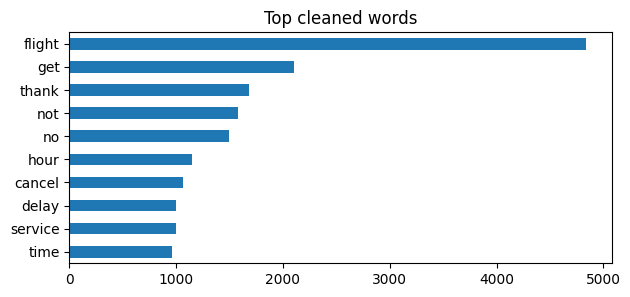

In [6]:
airlines = {'united', 'usairways', 'americanair', 'southwestair', 'jetblue',
            'virginamerica', 'american', 'southwest', 'delta', 'airline', 'airlines',
            'virgin', 'america', 'airways', 'flightled', 'u', 'us', 'please'}
df['final_tokens'] = df.lemmas.apply(lambda ws: [w for w in ws if w not in airlines])
df['joined_text'] = df.final_tokens.apply(' '.join)
raw_counts = Counter(w for ws in df.raw_tokens for w in ws)
counts = Counter(w for ws in df.final_tokens for w in ws)
print('Raw top tokens:', raw_counts.most_common(8))
pd.Series(dict(counts.most_common(10))).sort_values().plot.barh(title='Top cleaned words')
plt.show()

### B2 — Distinctive TF-IDF words and normalized comparison

Positive: thank, great, love, awesome, much
Negative: flight, hour, not, no, cancel


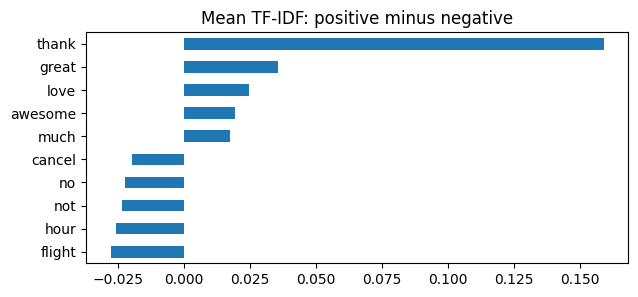

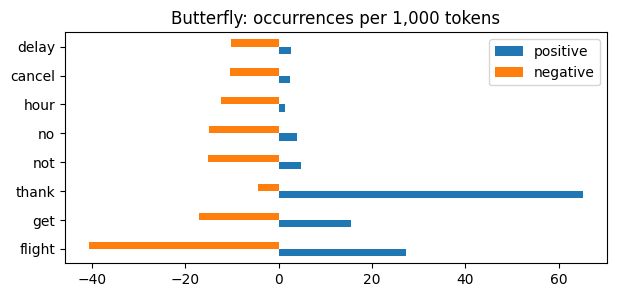

In [7]:
polar = df[df.airline_sentiment.isin(['positive', 'negative'])]
tfidf = TfidfVectorizer(min_df=10)
X = tfidf.fit_transform(polar.joined_text)
means = pd.DataFrame(index=tfidf.get_feature_names_out())
for group in ['positive', 'negative']:
    means[group] = np.asarray(X[(polar.airline_sentiment == group).values].mean(axis=0)).ravel()
means['difference'] = means.positive - means.negative
print('Positive:', ', '.join(means.nlargest(5, 'difference').index))
print('Negative:', ', '.join(means.nsmallest(5, 'difference').index))
means['difference'].sort_values().iloc[np.r_[0:5, -5:0]].plot.barh(title='Mean TF-IDF: positive minus negative')
plt.show()
comparison = pd.DataFrame(index=[w for w, count in counts.most_common(8)])
for group in ['positive', 'negative']:
    c = Counter(w for ws in df.loc[df.airline_sentiment == group, 'final_tokens'] for w in ws)
    comparison[group] = [1000*c[w]/sum(c.values()) for w in comparison.index]
comparison['negative'] *= -1
comparison.plot.barh(title='Butterfly: occurrences per 1,000 tokens'); plt.show()

### B3 — Bigrams, trigrams, and negation

In [8]:
negative = df[df.airline_sentiment == 'negative']
# Keep stop words: phrases must contain genuinely adjacent words.
phrases = negative.tokens.apply(' '.join)
for size in [2, 3]:
    cv = CountVectorizer(ngram_range=(size, size), min_df=3)
    Xn = cv.fit_transform(phrases)
    freq = pd.Series(np.asarray(Xn.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    print(f'Top {size}-grams:', freq.nlargest(5).to_dict())
for phrase in ['on hold', 'lost my bag', 'not good', 'not happy']:
    matches = negative.text.str.contains(phrase, case=False, regex=False)
    print(phrase, ':', matches.sum(), 'tweets')
display(pd.DataFrame({'phrase': ['good', 'not good', 'happy', 'not happy'],
                      'score': [score(t) for t in ['good', 'not good', 'happy', 'not happy']]}))

Top 2-grams: {'on hold': 505, 'customer service': 448, 'cancelled flightled': 445, 'on the': 429, 'my flight': 406}


Top 3-grams: {'on hold for': 235, 'been on hold': 165, 'was cancelled flightled': 96, 'on the phone': 85, 've been on': 73}
on hold : 491 tweets
lost my bag : 20 tweets
not good : 21 tweets
not happy : 23 tweets


,phrase,score
0,good,0.4404
1,not good,-0.3412
2,happy,0.5719
3,not happy,-0.4585


### B4 — Same words: cloud versus bars

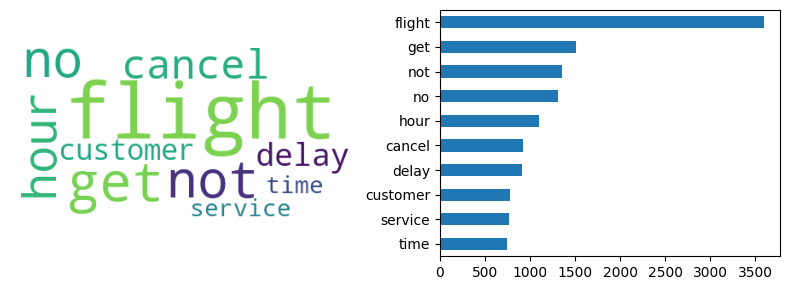

In [9]:
neg_counts = Counter(w for ws in negative.final_tokens for w in ws)
top = dict(neg_counts.most_common(10))
cloud = WordCloud(background_color='white', random_state=11).generate_from_frequencies(top)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(cloud); axes[0].axis('off')
pd.Series(top).sort_values().plot.barh(ax=axes[1])
plt.tight_layout(); plt.show()

## Part C — Sentiment Analysis
### C1 — Agreement, class metrics, and confusion matrix

Agreement: 0.543
Always-negative baseline: 0.627
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



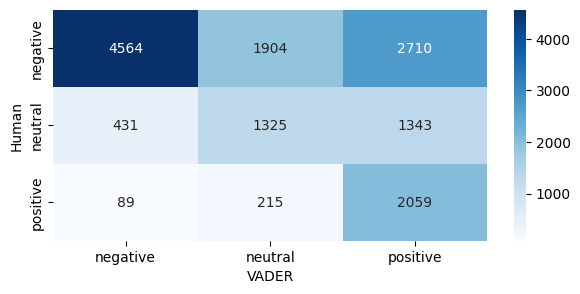

In [10]:
print('Agreement:', round((df.vader_label == df.airline_sentiment).mean(), 3))
print('Always-negative baseline:', round((df.airline_sentiment == 'negative').mean(), 3))
print(classification_report(df.airline_sentiment, df.vader_label, digits=2))
labels = ['negative', 'neutral', 'positive']
sns.heatmap(confusion_matrix(df.airline_sentiment, df.vader_label, labels=labels),
            annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('VADER'); plt.ylabel('Human'); plt.show()

### C2 — Strong disagreements and reviewed causes

In [11]:
errors = df[df.vader_label != df.airline_sentiment].copy()
target = errors.airline_sentiment.map({'negative': -1, 'neutral': 0, 'positive': 1})
errors['distance'] = (errors.vader_score - target).abs()
display(errors.nlargest(4, 'distance')[['text', 'airline_sentiment', 'vader_score']])
# Manual review of 40 strongest unique-tweet disagreements from the original analysis.
review = pd.Series({'Sarcasm': 13, 'Mixed / polite wording': 11, 'Implicit disruption': 6,
                    'Uncertain context / label': 4, 'Negation': 3, 'Wrong airline target': 3})
display(review.to_frame('Reviewed tweets (selected sample, not all errors)'))

,text,airline_sentiment,vader_score
5947,@SouthwestAir Report was filed but would like to support some acti...,negative,0.9716
2437,@united What a really GREAT &amp; FLATTERING story about you! You ...,negative,0.9467
7244,@JetBlue not an issue but I think training &amp; information would...,negative,0.9331
2421,@united Just let the employees know that good service and a kind a...,negative,0.9300


,"Reviewed tweets (selected sample, not all errors)"
Sarcasm,13
Mixed / polite wording,11
Implicit disruption,6
Uncertain context / label,4
Negation,3
Wrong airline target,3


### C3 — Run three constructed failures

In [12]:
examples = pd.DataFrame({'text': [
    'Wonderful, another cancelled flight. Just what I wanted!',
    'My suitcase never arrived at the destination.',
    'The crew was lovely and kind, but I am still stranded overnight.'],
    'intended': ['negative'] * 3})
examples['VADER score'] = examples.text.apply(score)
examples['prediction'] = examples['VADER score'].apply(label)
display(examples)

,text,intended,VADER score,prediction
0,"Wonderful, another cancelled flight. Just what I wanted!",negative,0.4574,positive
1,My suitcase never arrived at the destination.,negative,0.0000,neutral
2,"The crew was lovely and kind, but I am still stranded overnight.",negative,0.5574,positive


### C4 — High-confidence human labels

In [13]:
for name, sample in [('All', df), ('Confidence >= 0.9', df[df.airline_sentiment_confidence >= .9])]:
    print(name, '| tweets:', len(sample), '| accuracy:',
          round((sample.vader_label == sample.airline_sentiment).mean(), 3),
          '| negative share:', round((sample.airline_sentiment == 'negative').mean(), 3))

All | tweets: 14640 | accuracy: 0.543 | negative share: 0.627
Confidence >= 0.9 | tweets: 10458 | accuracy: 0.586 | negative share: 0.707


## Part D — Business Comparisons
### D1 — Complaint mix: service versus operations

,Service %,Operations %
airline,,
American,39.2,33.5
Delta,20.8,40.6
Southwest,33.0,35.2
US Airways,35.8,35.7
United,25.9,37.9
Virgin America,33.1,24.3


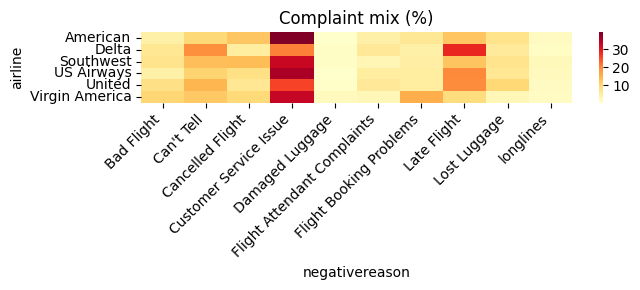

In [14]:
mix = pd.crosstab(negative.airline, negative.negativereason)
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
operations = ['Late Flight', 'Cancelled Flight', 'Lost Luggage', 'Damaged Luggage']
families = pd.DataFrame({'Service %': mix_pct['Customer Service Issue'],
                         'Operations %': mix_pct[operations].sum(axis=1)})
display(families.round(1))
sns.heatmap(mix_pct, cmap='YlOrRd'); plt.title('Complaint mix (%)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

### D2 — Counts versus percentages

,Negative count,Negative %
airline,,
American,1960,71.0
Delta,955,43.0
Southwest,1186,49.0
US Airways,2263,77.7
United,2633,68.9
Virgin America,181,35.9


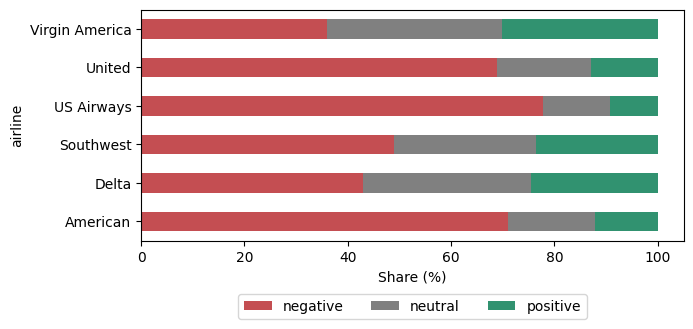

In [15]:
totals = pd.crosstab(df.airline, df.airline_sentiment)
percent = totals.div(totals.sum(axis=1), axis=0) * 100
display(pd.DataFrame({'Negative count': totals.negative, 'Negative %': percent.negative.round(1)}))
percent[['negative', 'neutral', 'positive']].plot.barh(stacked=True, color=['#c44e52', 'gray', '#319270'])
plt.xlabel('Share (%)'); plt.legend(loc='upper center', bbox_to_anchor=(.5, -.2), ncol=3); plt.show()

### D3 — Daily sentiment spikes

,total,negative,negative %
date,,,
2015-02-17,953,552,57.9
2015-02-18,1416,827,58.4
2015-02-19,1298,666,51.3
2015-02-20,1512,849,56.2
2015-02-21,1418,901,63.5
2015-02-22,2392,1744,72.9
2015-02-23,3515,2346,66.7
2015-02-24,2136,1293,60.5


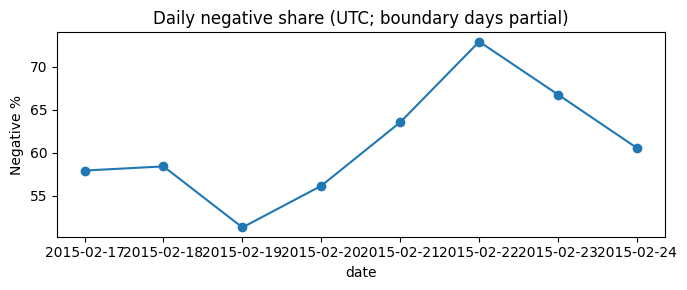

In [16]:
daily = df.groupby(df.date.dt.date).airline_sentiment.agg(
    total='size', negative=lambda s: (s == 'negative').sum())
daily['negative %'] = daily.negative / daily.total * 100
display(daily.round(1))
daily['negative %'].plot(marker='o', title='Daily negative share (UTC; boundary days partial)')
plt.ylabel('Negative %'); plt.tight_layout(); plt.show()

### D4 — Implement a response queue

In [17]:
queue = negative.copy()
urgent = queue.text.str.contains(r'\b(?:stranded|stuck|urgent|medical|overnight|wheelchair)\b', case=False)
unresolved = queue.text.str.contains(r'on hold|still waiting|no response|hours?', case=False)
disruption = queue.negativereason.isin(['Lost Luggage', 'Cancelled Flight'])
queue['priority'] = np.select([urgent, unresolved | disruption], [1, 2], default=3)
queue = queue.sort_values(['priority', 'date'])
display(queue[['priority', 'airline', 'text']].head(4))
print(queue.priority.value_counts().sort_index())

,priority,airline,text
6742,1,Southwest,@SouthwestAir We have been stuck in SJU for several hours and no o...
4265,1,United,@united I somehow think I'm going to be stuck paying for a hotel r...
6616,1,Southwest,@SouthwestAir I understand a delay but to be stuck on the plane lo...
6578,1,Southwest,@SouthwestAir you Cancelled Flightled my flight to BNA. I have fli...


priority
1     275
2    2677
3    6226
Name: count, dtype: int64


## Part E — Limits and Decisions
### E1 — Sampling bias

In [18]:
print('Tweets by airline:', df.airline.value_counts().to_dict())
print('Repeated tweet IDs:', df.tweet_id.duplicated().sum())
print('Tweets from repeated handles:', round(df.name.duplicated(keep=False).mean(), 3))

Tweets by airline: {'United': 3822, 'US Airways': 2913, 'American': 2759, 'Southwest': 2420, 'Delta': 2222, 'Virgin America': 504}
Repeated tweet IDs: 155
Tweets from repeated handles: 0.679


### E2 — Historical coverage

In [19]:
print('First:', df.date.min(), '| Last:', df.date.max())

First: 2015-02-17 07:36:05+00:00 | Last: 2015-02-24 19:53:37+00:00


### E3 — Should automation replace manual review?

In [20]:
human_negative = df.airline_sentiment == 'negative'
missed = human_negative & (df.vader_label != 'negative')
print('Human-negative tweets missed:', missed.sum())
print('Miss rate:', round(missed.sum() / human_negative.sum(), 3))

Human-negative tweets missed: 4614
Miss rate: 0.503


## Part F — Three Additional Insights
### F1 — Repeated customer contact

In [21]:
posts = negative.groupby('name').size()
repeat = negative.name.isin(posts[posts > 1].index)
print('Negative tweets from repeat negative posters:', round(repeat.mean(), 3))

Negative tweets from repeat negative posters: 0.662


### F2 — Source-text anomalies

In [22]:
for phrase in ['Flightled', 'Cancelled Flight', 'Late Flight']:
    print(phrase, ':', df.text.str.contains(phrase, case=False, regex=False).sum())

Flightled : 501
Cancelled Flight : 1020
Late Flight : 451


### F3 — Public amplification

In [23]:
reach = df.groupby('airline_sentiment').retweet_count.agg(
    median='median', retweeted_share=lambda s: (s > 0).mean() * 100)
display(reach.round(2))

,median,retweeted_share
airline_sentiment,,
negative,0.0,6.50
neutral,0.0,3.03
positive,0.0,3.22
